In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ariya\Downloads\Bengaluru_House_Data.csv")

df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [4]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [5]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [6]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [7]:
df = df.drop(columns=['society'])

In [8]:
df['bhk'] = df['size'].str.extract(r'(\d+)').astype(float)

In [9]:
df[['size', 'bhk']].head(10)

,size,bhk
0,2 BHK,2.0
1,4 Bedroom,4.0
2,3 BHK,3.0
3,3 BHK,3.0
4,2 BHK,2.0
5,2 BHK,2.0
6,4 BHK,4.0
7,4 BHK,4.0
8,3 BHK,3.0
9,6 Bedroom,6.0


In [10]:
def convert_sqft_to_num(x):
    try:
        if '-' in x:
            values = x.split('-')
            return (float(values[0]) + float(values[1])) / 2
        return float(x)
    except:
        return np.nan

In [11]:
df['total_sqft'] = df['total_sqft'].apply(convert_sqft_to_num)

In [12]:
df['total_sqft'].dtype

dtype('float64')

In [13]:
df = df.dropna(
    subset=['location', 'bhk', 'total_sqft']
)

In [14]:
df['bath'] = df['bath'].fillna(df['bath'].median())

df['balcony'] = df['balcony'].fillna(df['balcony'].median())

In [15]:
df.isnull().sum()

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64

In [16]:
df = df.drop(columns=['size'])

In [17]:
df = df[df['total_sqft'] >= 300]

In [18]:
df['sqft_per_bhk'] = df['total_sqft'] / df['bhk']

In [19]:
df = df[df['sqft_per_bhk'] >= 300]

In [20]:
df['price_per_sqft'] = (
    df['price'] * 100000 / df['total_sqft']
)

In [21]:
df[['total_sqft', 'price', 'price_per_sqft']].head()

,total_sqft,price,price_per_sqft
0,1056.0,39.07,3699.810606
1,2600.0,120.00,4615.384615
2,1440.0,62.00,4305.555556
3,1521.0,95.00,6245.890861
4,1200.0,51.00,4250.000000


In [22]:
print("Final dataset shape:", df.shape)

df.head()

Final dataset shape: (12513, 10)


,area_type,availability,location,total_sqft,bath,balcony,price,bhk,sqft_per_bhk,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2.0,528.0,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4.0,650.0,4615.384615
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3.0,480.0,4305.555556
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3.0,507.0,6245.890861
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2.0,600.0,4250.000000


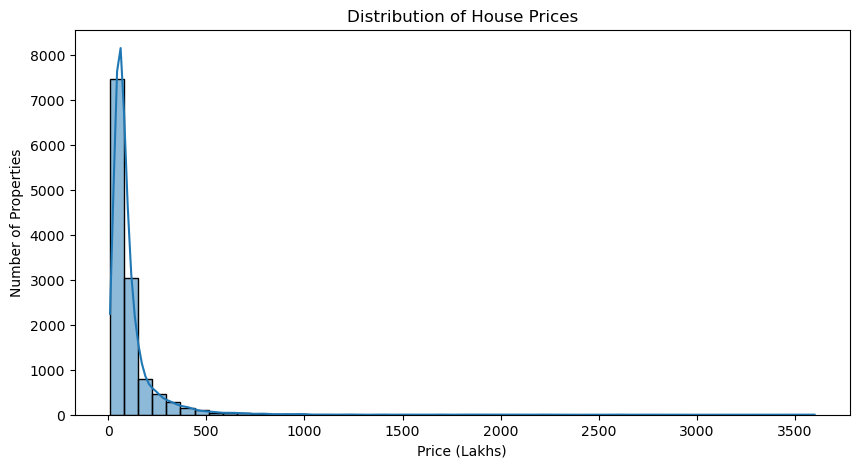

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], bins=50, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Number of Properties')

plt.show()

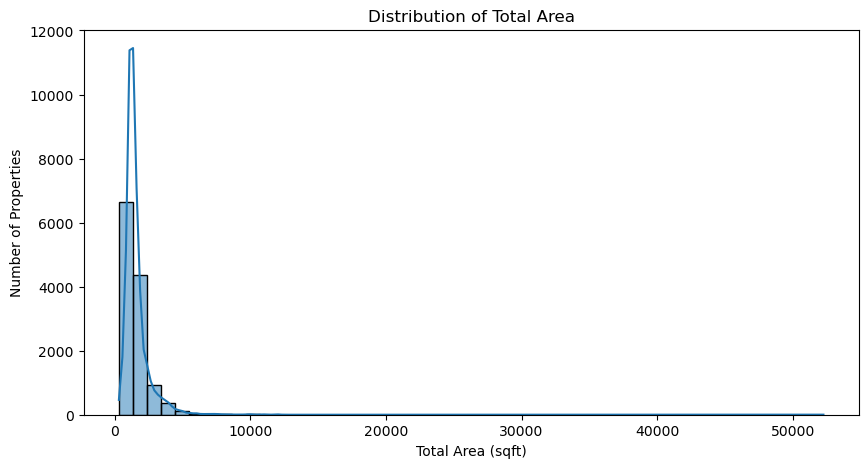

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(df['total_sqft'], bins=50, kde=True)

plt.title('Distribution of Total Area')
plt.xlabel('Total Area (sqft)')
plt.ylabel('Number of Properties')

plt.show()

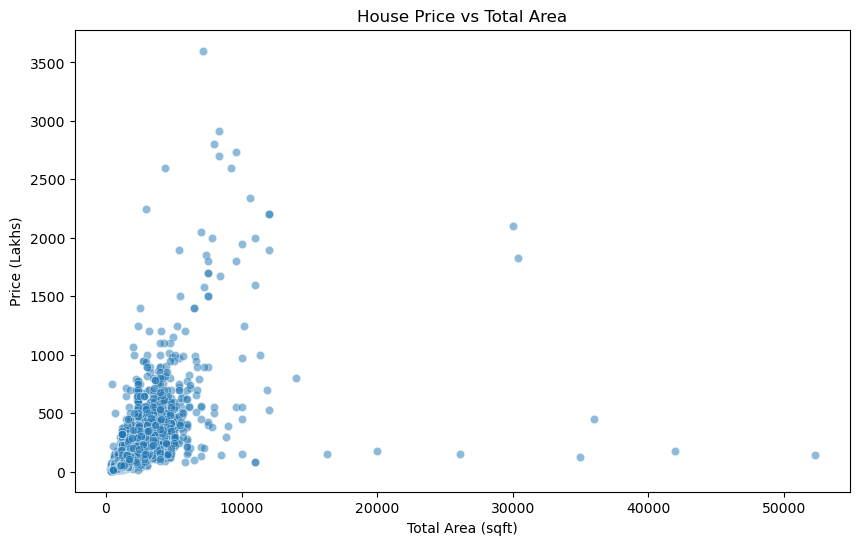

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_sqft',
    y='price',
    alpha=0.5
)

plt.title('House Price vs Total Area')
plt.xlabel('Total Area (sqft)')
plt.ylabel('Price (Lakhs)')

plt.show()

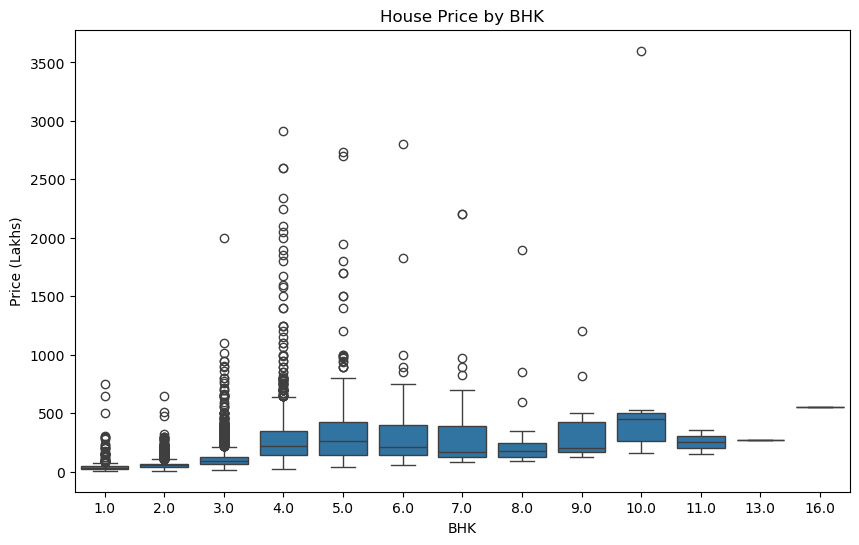

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='bhk',
    y='price'
)

plt.title('House Price by BHK')
plt.xlabel('BHK')
plt.ylabel('Price (Lakhs)')

plt.show()

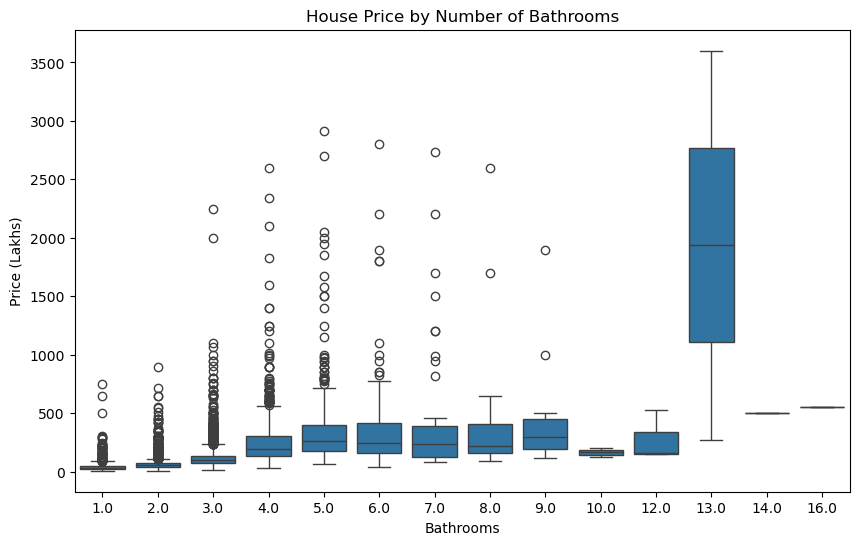

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='bath',
    y='price'
)

plt.title('House Price by Number of Bathrooms')
plt.xlabel('Bathrooms')
plt.ylabel('Price (Lakhs)')

plt.show()

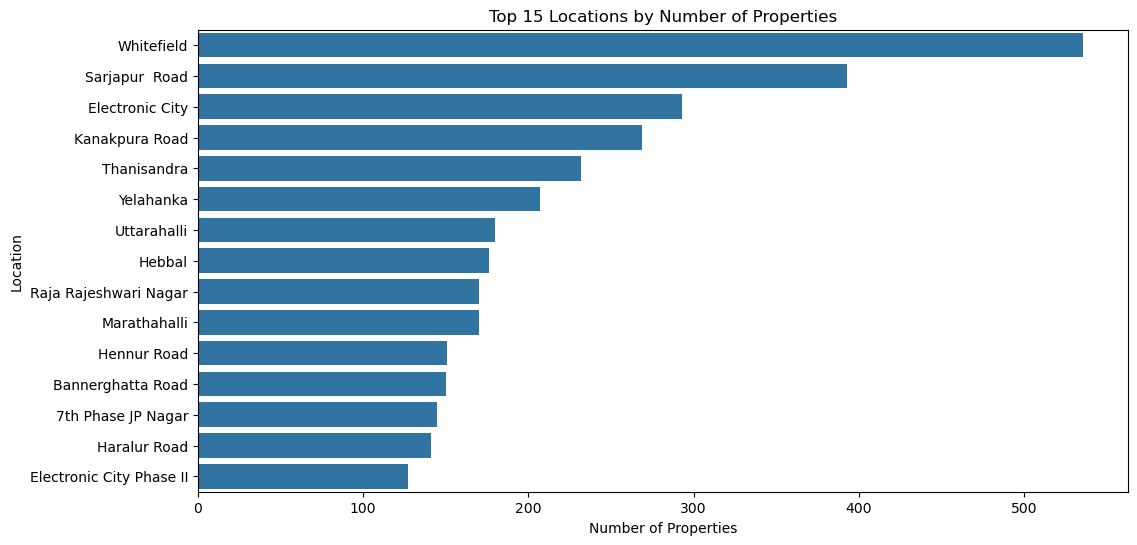

In [28]:
top_locations = df['location'].value_counts().head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title('Top 15 Locations by Number of Properties')
plt.xlabel('Number of Properties')
plt.ylabel('Location')

plt.show()

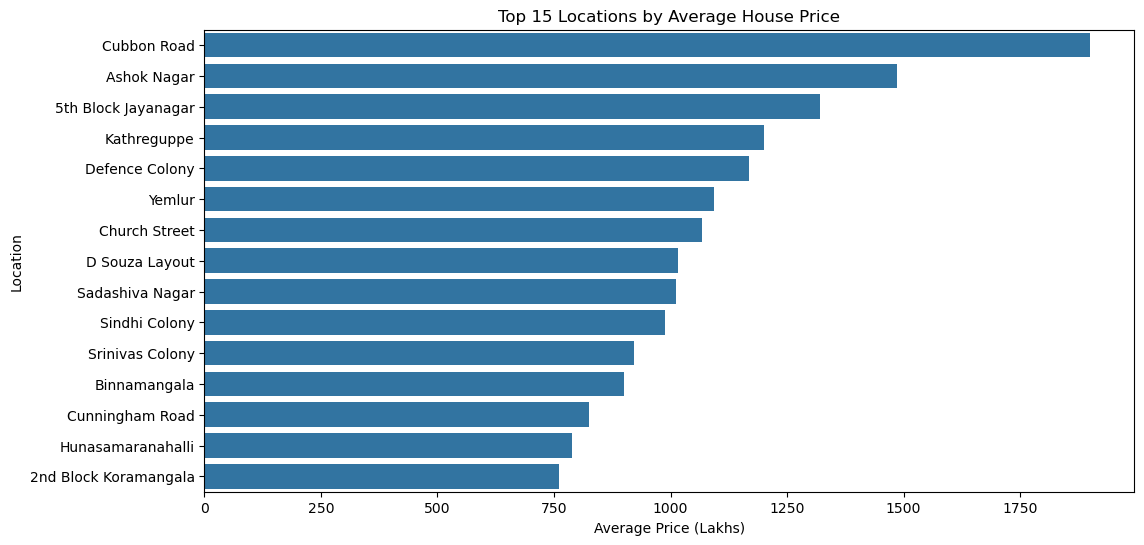

In [29]:
location_price = (
    df.groupby('location')['price']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=location_price.values,
    y=location_price.index
)

plt.title('Top 15 Locations by Average House Price')
plt.xlabel('Average Price (Lakhs)')
plt.ylabel('Location')

plt.show()

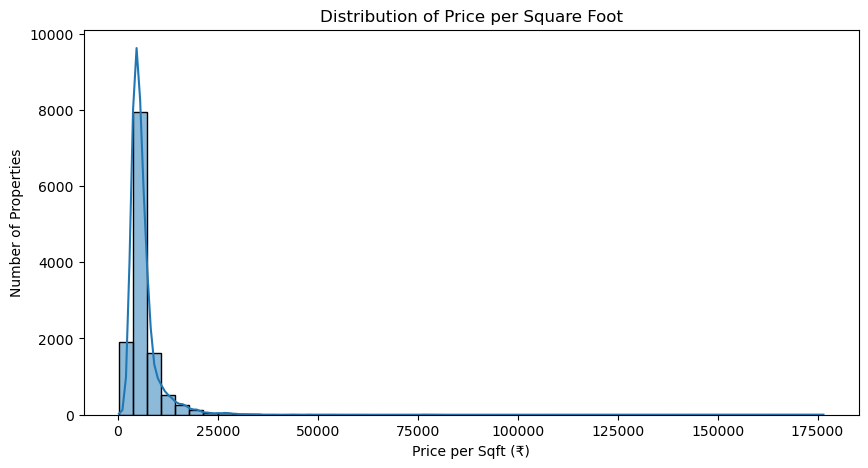

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['price_per_sqft'],
    bins=50,
    kde=True
)

plt.title('Distribution of Price per Square Foot')
plt.xlabel('Price per Sqft (₹)')
plt.ylabel('Number of Properties')

plt.show()

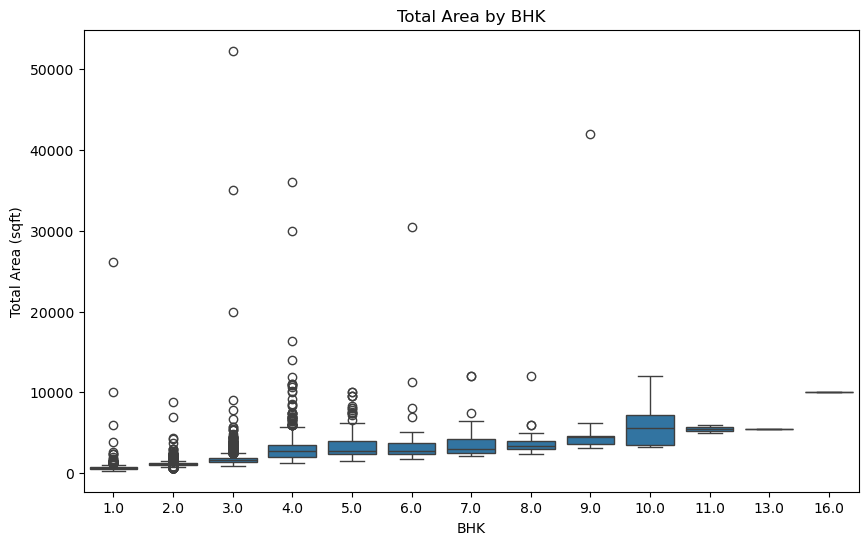

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='bhk',
    y='total_sqft'
)

plt.title('Total Area by BHK')
plt.xlabel('BHK')
plt.ylabel('Total Area (sqft)')

plt.show()

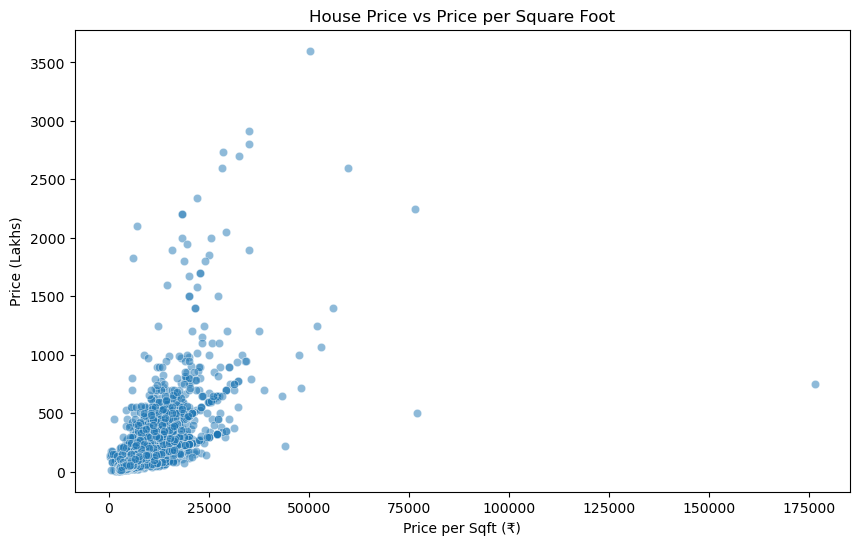

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='price_per_sqft',
    y='price',
    alpha=0.5
)

plt.title('House Price vs Price per Square Foot')
plt.xlabel('Price per Sqft (₹)')
plt.ylabel('Price (Lakhs)')

plt.show()

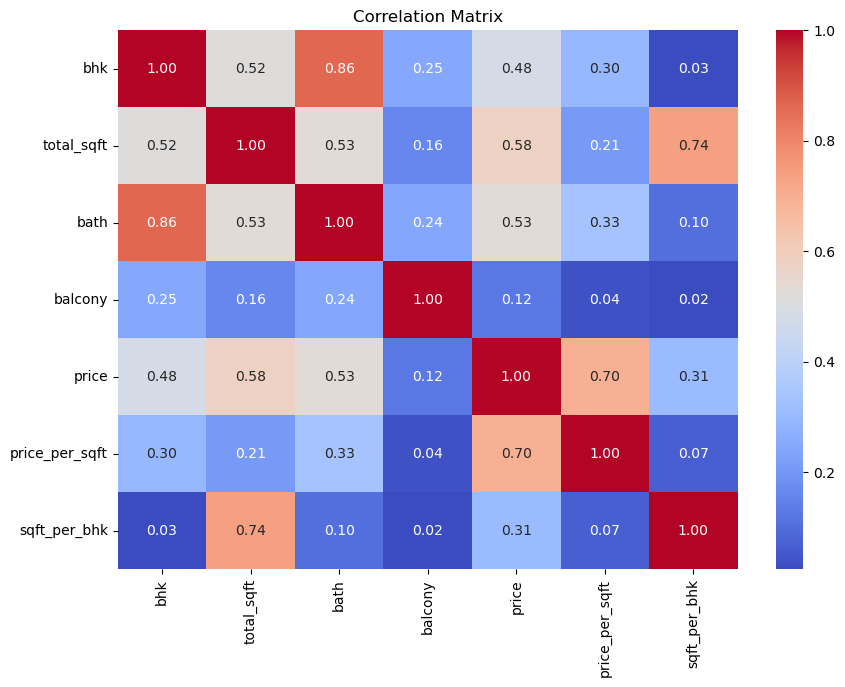

In [33]:
numeric_cols = [
    'bhk',
    'total_sqft',
    'bath',
    'balcony',
    'price',
    'price_per_sqft',
    'sqft_per_bhk'
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

In [34]:
df_model = df.drop(
    columns=['price_per_sqft', 'sqft_per_bhk'],
    errors='ignore'
)

In [35]:
X = df_model.drop(columns=['price'])
y = df_model['price']

In [36]:
categorical_features = [
    'area_type',
    'availability',
    'location'
]

numerical_features = [
    'total_sqft',
    'bhk',
    'bath',
    'balcony'
]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (10010, 7)
Testing data: (2503, 7)


In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

In [39]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_lr = linear_model.predict(X_test)

In [40]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression
MAE : 42.53905821378892
RMSE: 96.1302329173166
R²  : 0.5545168007355894


In [41]:
decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ))
])

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)

In [42]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(
    mean_squared_error(y_test, y_pred_dt)
)

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R²  :", r2_dt)

Decision Tree
MAE : 37.75888052324934
RMSE: 121.66052288719023
R²  : 0.28647252914612165


In [43]:
random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        max_depth=15
    ))
])

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

In [44]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest
MAE : 31.99649145092782
RMSE: 86.94466206932509
R²  : 0.6355842084162748


In [45]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        mae_lr,
        mae_dt,
        mae_rf
    ],
    'RMSE': [
        rmse_lr,
        rmse_dt,
        rmse_rf
    ],
    'R2': [
        r2_lr,
        r2_dt,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,42.539058,96.130233,0.554517
1,Decision Tree,37.758881,121.660523,0.286473
2,Random Forest,31.996491,86.944662,0.635584


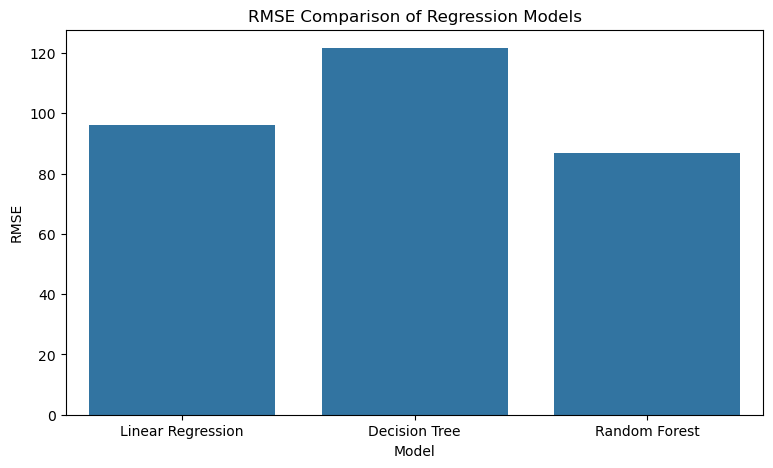

In [46]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title('RMSE Comparison of Regression Models')
plt.xlabel('Model')
plt.ylabel('RMSE')

plt.show()

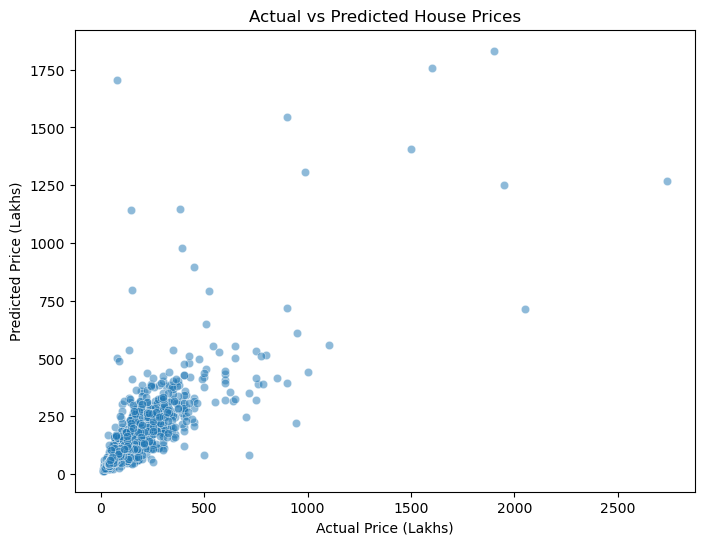

In [47]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_rf,
    alpha=0.5
)

plt.xlabel('Actual Price (Lakhs)')
plt.ylabel('Predicted Price (Lakhs)')
plt.title('Actual vs Predicted House Prices')

plt.show()

In [48]:
feature_names = (
    random_forest
    .named_steps['preprocessor']
    .get_feature_names_out()
)

rf_model = random_forest.named_steps['model']

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

top_5_features = feature_importance.head(5)

top_5_features

,Feature,Importance
1201,remainder__total_sqft,0.641532
392,categorical__location_Defence Colony,0.029759
1202,remainder__bath,0.029190
1204,remainder__bhk,0.024033
82,categorical__availability_Ready To Move,0.023889


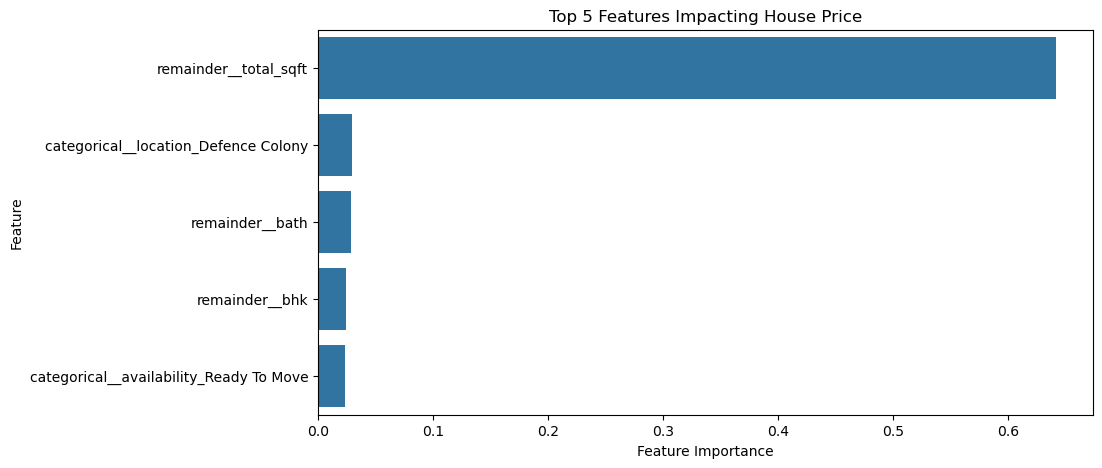

In [49]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 5 Features Impacting House Price')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.show()

Project Conclusion

In this project, a machine learning model was developed to predict house prices in Bengaluru using property-related features such as total square footage, BHK, bathrooms, location, area type and availability.

Three regression algorithms were evaluated: Linear Regression, Decision Tree Regression and Random Forest Regression. Based on MAE, RMSE and R², Random Forest performed the best, achieving an MAE of 31.996, RMSE of 86.945 and R² of 0.6356.

The Random Forest model explained approximately 63.56% of the variation in house prices in the test dataset. Feature-importance analysis showed that total square footage was the most influential feature, followed by specific location, number of bathrooms, BHK and availability status.

The results demonstrate that machine learning can help estimate Bengaluru property prices and provide useful insights into the factors associated with property value.